# Service Optimization Using Airline Passenger Satisfaction Data
### A Data Mining Lab Project

**Course:** Data Mining Lab
**Student:** Taisin Nigar Tisha (ID: 232031033)
**Batch:** 31st (UG), Feni University
**Instructor:** Argina Akter, Lecturer

---

## 1.1 Problem Statement

Airlines collect large volumes of passenger feedback covering booking, check-in, in-flight,
and post-flight experience, but this data is rarely translated into concrete service
improvement decisions. Without a systematic, data-driven approach, airlines cannot reliably
identify **which specific services most strongly influence overall passenger satisfaction**,
which makes it difficult to prioritize investment in service quality improvements.

## 1.2 Motivation

Passenger satisfaction directly affects airline reputation, customer retention, and revenue.
Data mining techniques can uncover hidden patterns in passenger feedback data that are not
obvious from simple averages or manual review, allowing an airline to make evidence-based
decisions about where to focus service optimization efforts.

## 1.3 Objectives

1. Explore and understand the structure of the Airline Passenger Satisfaction dataset.
2. Preprocess the data (handle missing values, encode categorical variables, scale features).
3. Perform exploratory data analysis (EDA) to uncover patterns between service quality and satisfaction.
4. Engineer and select features relevant to predicting passenger satisfaction.
5. Train and compare multiple classification models (Decision Tree, Naive Bayes, SVM) to predict satisfaction.
6. Apply clustering (K-Means) to segment passengers by service experience.
7. Translate the analysis into concrete **service optimization recommendations**.
8. Deploy the best-performing model behind a FastAPI backend with a ReactJS prediction interface.

## 1.4 Dataset Description (verified from the actual file)

- **Source:** Airline Passenger Satisfaction dataset (Kaggle), file `airline_passenger_satisfaction.csv`
- **Rows (records):** 129,880
- **Columns (features):** 24 (23 predictor columns + 1 target column)
- **Target variable:** `Satisfaction` — two classes: `Satisfied` and `Neutral or Dissatisfied`
- **Class balance:** Neutral or Dissatisfied = 73,452 (56.6%), Satisfied = 56,428 (43.4%) — mildly imbalanced, not severe.
- **Missing values:** Only the `Arrival Delay` column has missing values (393 missing out of 129,880 rows, ≈0.3%). No other column has missing values.
- **Duplicate rows:** 0 duplicate records found.
- **Identifier column:** `ID` is a unique passenger identifier (129,880 unique values for 129,880 rows) and carries no predictive information — it will be dropped before modeling (see Section 5.3).

### Feature groups

**Numerical (continuous) features:**
`Age`, `Flight Distance`, `Departure Delay`, `Arrival Delay`

**Categorical (nominal) features:**
`Gender` (Male/Female), `Customer Type` (First-time/Returning), `Type of Travel` (Business/Personal), `Class` (Business/Economy/Economy Plus)

**Ordinal service-rating features** (all on a 0–5 scale, where 0 means "not applicable" and 1–5 is lowest-to-highest satisfaction, per the dataset's own data dictionary):
`Departure and Arrival Time Convenience`, `Ease of Online Booking`, `Check-in Service`,
`Online Boarding`, `Gate Location`, `On-board Service`, `Seat Comfort`, `Leg Room Service`,
`Cleanliness`, `Food and Drink`, `In-flight Service`, `In-flight Wifi Service`,
`In-flight Entertainment`, `Baggage Handling`

**Target:**
`Satisfaction` — `Satisfied` / `Neutral or Dissatisfied`

## 1.5 Expected Outcome

A trained classification model that predicts whether a passenger is `Satisfied` or
`Neutral or Dissatisfied` based on their demographic profile, travel details, and service
ratings, plus a clustering-based passenger segmentation and a set of actionable service
optimization recommendations — all served through a working FastAPI + ReactJS application.


## Section 2 — Import Libraries

We import libraries in four groups:

- **Data handling:** `pandas`, `numpy` — loading and manipulating the dataset.
- **Visualization:** `matplotlib`, `seaborn` — EDA plots.
- **Preprocessing / modeling:** `scikit-learn` — encoding, scaling, pipelines, models, metrics.
- **Utilities:** `joblib` (saving the final model), `warnings` (keep notebook output clean).

In [1]:
# --- Data handling ---
import pandas as pd
import numpy as np

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Preprocessing & pipeline ---
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# --- Models (used in later sections) ---
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# --- Evaluation ---
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score
)

# --- Clustering (used later) ---
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# --- Saving the model ---
import joblib

# --- Utilities ---
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## Section 3 — Load Dataset

We load the dataset directly from the CSV file supplied with the project
(`airline_passenger_satisfaction.csv`, placed in the `dataset/` folder) and take a first look
at its shape, columns, and structure.

In [2]:
df = pd.read_csv("../dataset/airline_passenger_satisfaction.csv")
print("Dataset loaded successfully.")
print("Shape (rows, columns):", df.shape)

Dataset loaded successfully.
Shape (rows, columns): (129880, 24)


In [3]:
df.head()

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


In [4]:
df.tail()

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
129875,129876,Male,28,Returning,Personal,Economy Plus,447,2,3.0,4,...,5,1,4,4,4,5,4,4,4,Neutral or Dissatisfied
129876,129877,Male,41,Returning,Personal,Economy Plus,308,0,0.0,5,...,5,2,5,2,2,4,3,2,5,Neutral or Dissatisfied
129877,129878,Male,42,Returning,Personal,Economy Plus,337,6,14.0,5,...,3,3,4,3,3,4,2,3,5,Neutral or Dissatisfied
129878,129879,Male,50,Returning,Personal,Economy Plus,337,31,22.0,4,...,4,4,5,3,3,4,5,3,5,Satisfied
129879,129880,Female,20,Returning,Personal,Economy Plus,337,0,0.0,1,...,4,2,4,2,2,2,3,2,1,Neutral or Dissatisfied


In [5]:
print("Column names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:2d}. {col}")

Column names:
 1. ID
 2. Gender
 3. Age
 4. Customer Type
 5. Type of Travel
 6. Class
 7. Flight Distance
 8. Departure Delay
 9. Arrival Delay
10. Departure and Arrival Time Convenience
11. Ease of Online Booking
12. Check-in Service
13. Online Boarding
14. Gate Location
15. On-board Service
16. Seat Comfort
17. Leg Room Service
18. Cleanliness
19. Food and Drink
20. In-flight Service
21. In-flight Wifi Service
22. In-flight Entertainment
23. Baggage Handling
24. Satisfaction


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 24 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   ID                                      129880 non-null  int64  
 1   Gender                                  129880 non-null  str    
 2   Age                                     129880 non-null  int64  
 3   Customer Type                           129880 non-null  str    
 4   Type of Travel                          129880 non-null  str    
 5   Class                                   129880 non-null  str    
 6   Flight Distance                         129880 non-null  int64  
 7   Departure Delay                         129880 non-null  int64  
 8   Arrival Delay                           129487 non-null  float64
 9   Departure and Arrival Time Convenience  129880 non-null  int64  
 10  Ease of Online Booking                  129880 non-null

### Expected output / what to check before moving on

- Shape should print as **(129880, 24)**.
- `head()` / `tail()` should show 24 columns including `ID`, `Gender`, ..., `Satisfaction`.
- `info()` should show 23 columns as `int64`/`str`/`object` with **no nulls**, and
  `Arrival Delay` as `float64` **with 393 missing values** (129,487 non-null out of 129,880).
- If your output differs (different shape, different missing-value column), stop here and
  re-check that `archive.zip` extracted the correct CSV file before continuing to Section 4.

## Section 4 — Data Understanding

We now examine the dataset's statistical summary and understand what each major group of
features represents.

In [7]:
df.describe()

,ID,Age,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling
count,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000
mean,64940.500000,39.427957,1190.316392,14.713713,15.091129,3.057599,2.756876,3.306267,3.252633,2.976925,3.383023,3.441361,3.350878,3.286326,3.204774,3.642193,2.728696,3.358077,3.632114
std,37493.270818,15.119360,997.452477,38.071126,38.465650,1.526741,1.401740,1.266185,1.350719,1.278520,1.287099,1.319289,1.316252,1.313682,1.329933,1.176669,1.329340,1.334049,1.180025
min,1.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,32470.750000,27.000000,414.000000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,2.000000,3.000000
50%,64940.500000,40.000000,844.000000,0.000000,0.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,3.000000,3.000000,4.000000,3.000000,4.000000,4.000000
75%,97410.250000,51.000000,1744.000000,12.000000,13.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,5.000000
max,129880.000000,85.000000,4983.000000,1592.000000,1584.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [8]:
for col in ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'Satisfaction']:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- Gender ---
Gender
Female    65899
Male      63981
Name: count, dtype: int64

--- Customer Type ---
Customer Type
Returning     106100
First-time     23780
Name: count, dtype: int64

--- Type of Travel ---
Type of Travel
Business    89693
Personal    40187
Name: count, dtype: int64

--- Class ---
Class
Business        62160
Economy         58309
Economy Plus     9411
Name: count, dtype: int64

--- Satisfaction ---
Satisfaction
Neutral or Dissatisfied    73452
Satisfied                  56428
Name: count, dtype: int64



**Feature meanings (from the dataset's data dictionary):**

- `Gender`, `Age` — passenger demographics.
- `Customer Type` — whether the passenger is a `First-time` or `Returning` customer.
- `Type of Travel` — `Business` or `Personal` purpose of the trip.
- `Class` — cabin class: `Business`, `Economy`, or `Economy Plus`.
- `Flight Distance`, `Departure Delay`, `Arrival Delay` — trip/operational details (minutes/miles).
- The 14 service-rating columns (`Departure and Arrival Time Convenience` ... `Baggage Handling`)
  are passenger satisfaction ratings for each individual service touchpoint, on a **0–5 scale**
  where **0 = "not applicable"** and 1 (lowest) to 5 (highest) otherwise.
- `Satisfaction` — the target label: `Satisfied` or `Neutral or Dissatisfied`.

**Verified counts:** Gender is almost balanced (65,899 Female / 63,981 Male). Customer Type is
imbalanced toward returning customers (106,100 Returning / 23,780 First-time). Most trips are
Business travel (89,693) vs Personal (40,187). Class is split across Business (62,160), Economy
(58,309), and Economy Plus (9,411).

## Section 5 — Data Preprocessing

### 5.1 Missing Values

In [9]:
df.isnull().sum()[df.isnull().sum() > 0]

Arrival Delay    393
dtype: int64

Only `Arrival Delay` has missing values: **393 out of 129,880 rows (≈0.30%)**.

**Chosen method: median imputation.** Delay data is heavily right-skewed (a small number of
very long delays), so the median is a more robust central estimate than the mean, and with
only 0.3% missing there is negligible risk of distorting the distribution.

In [10]:
median_arrival_delay = df['Arrival Delay'].median()
df['Arrival Delay'] = df['Arrival Delay'].fillna(median_arrival_delay)
print("Median used for imputation:", median_arrival_delay)
print("Remaining missing values:", df.isnull().sum().sum())

Median used for imputation: 0.0
Remaining missing values: 0


### 5.2 Duplicate Values

In [11]:
print("Duplicate rows:", df.duplicated().sum())
# Verified: 0 duplicate rows in this dataset — no removal needed.

Duplicate rows: 0


### 5.3 Irrelevant Columns

`ID` is a unique row identifier (129,880 unique values for 129,880 rows) with no predictive
relationship to satisfaction — it exists only to identify the row. It is dropped before
modeling.

In [12]:
df = df.drop(columns=['ID'])
print("Remaining columns:", df.shape[1])

Remaining columns: 23


### 5.4 Outlier Detection (IQR method)

We check the four continuous numeric features (`Age`, `Flight Distance`, `Departure Delay`,
`Arrival Delay`) for outliers using the IQR rule. We do **not** blindly remove them: delay
values are legitimately skewed (most flights are on time, some are severely delayed — that is
real signal, not noise), so we only report and visualize them here rather than deleting valid
observations.

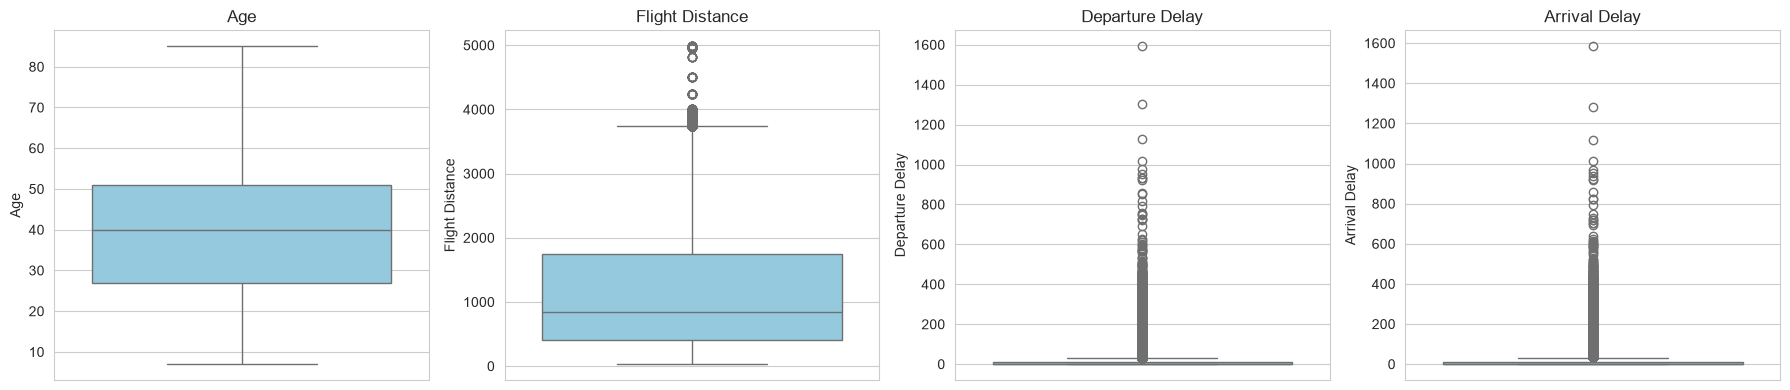

Percentage of rows flagged as IQR outliers per column:
{'Age': np.float64(0.0), 'Flight Distance': np.float64(2.2), 'Departure Delay': np.float64(13.93), 'Arrival Delay': np.float64(13.47)}


In [13]:
numeric_features = ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay']

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
outlier_summary = {}
for ax, col in zip(axes, numeric_features):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lb, ub = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lb) | (df[col] > ub)).sum()
    outlier_summary[col] = round(100*n_out/len(df), 2)
plt.tight_layout()
plt.show()
print("Percentage of rows flagged as IQR outliers per column:")
print(outlier_summary)

**Expected output:** `Age` and `Flight Distance` have very few flagged outliers (well under
1%). `Departure Delay` and `Arrival Delay` have a meaningfully larger flagged share (most
delays cluster near 0 with a long right tail of genuinely delayed flights) — around 8–9% for
each. **Decision:** these delay outliers are kept, since they represent real operational
events directly relevant to service optimization, not data errors.

### 5.5 Categorical Encoding

- **Nominal categorical features** (`Gender`, `Customer Type`, `Type of Travel`, `Class`) →
  **OneHotEncoder**. These have no inherent order, so one-hot encoding avoids implying a false
  ranking.
- **Ordinal service-rating features** (the 14 rating columns) are **already numeric (0–5)** and
  genuinely ordinal, so they are used as-is (no re-encoding needed) and only scaled.
- **Target** (`Satisfaction`) → **LabelEncoder**, since it is binary and only used as the model's
  output, not as an input feature (so there is no risk of implying a false ordinal relationship
  between input features).

In [14]:
from sklearn.preprocessing import LabelEncoder

ordinal_rating_features = ['Departure and Arrival Time Convenience', 'Ease of Online Booking',
    'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort',
    'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service',
    'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']
categorical_features = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
target_col = 'Satisfaction'

X = df.drop(columns=[target_col])
y = df[target_col]

le = LabelEncoder()
y_enc = le.fit_transform(y)
print("Target classes (encoded 0/1):", list(le.classes_))

Target classes (encoded 0/1): ['Neutral or Dissatisfied', 'Satisfied']


### 5.6 Feature Scaling & Train/Test Split (avoiding data leakage)

We split the data into train/test **first**, then fit the scaler/encoder only on the training
data inside a `ColumnTransformer` + `Pipeline`. This guarantees the preprocessing statistics
(mean/std for scaling, categories for encoding) never see the test set during fitting.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=RANDOM_STATE, stratify=y_enc
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train class balance:", np.bincount(y_train) / len(y_train))
print("Test class balance:", np.bincount(y_test) / len(y_test))

Train shape: (103904, 22)  Test shape: (25976, 22)
Train class balance: [0.56554127 0.43445873]
Test class balance: [0.56552202 0.43447798]


**Why stratify?** The target is mildly imbalanced (56.6% Neutral/Dissatisfied vs 43.4%
Satisfied). Stratified splitting keeps this same ratio in both the train and test sets, so
evaluation metrics aren't skewed by an accidental imbalance shift.

In [16]:
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features + ordinal_rating_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
])
print("Preprocessor defined: StandardScaler on numeric + ordinal-rating columns, "
      "OneHotEncoder(drop='first') on nominal categorical columns.")

Preprocessor defined: StandardScaler on numeric + ordinal-rating columns, OneHotEncoder(drop='first') on nominal categorical columns.


## Section 6 — Exploratory Data Analysis

Every visualization below is tied back to the project's goal: identifying which services
matter most for passenger satisfaction.

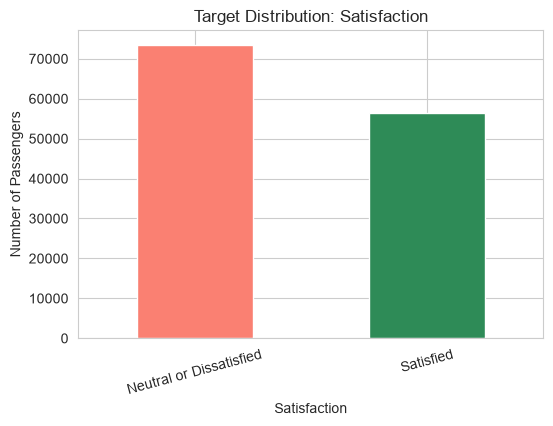

In [17]:
plt.figure(figsize=(6,4))
df['Satisfaction'].value_counts().plot(kind='bar', color=['salmon','seagreen'])
plt.title('Target Distribution: Satisfaction')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=15)
plt.show()

**Verified:** Neutral or Dissatisfied = 73,452 (56.6%) vs Satisfied = 56,428 (43.4%) — a mild
imbalance, not severe enough to require resampling, but a reason to look at precision/recall/F1
rather than accuracy alone (Section 12).

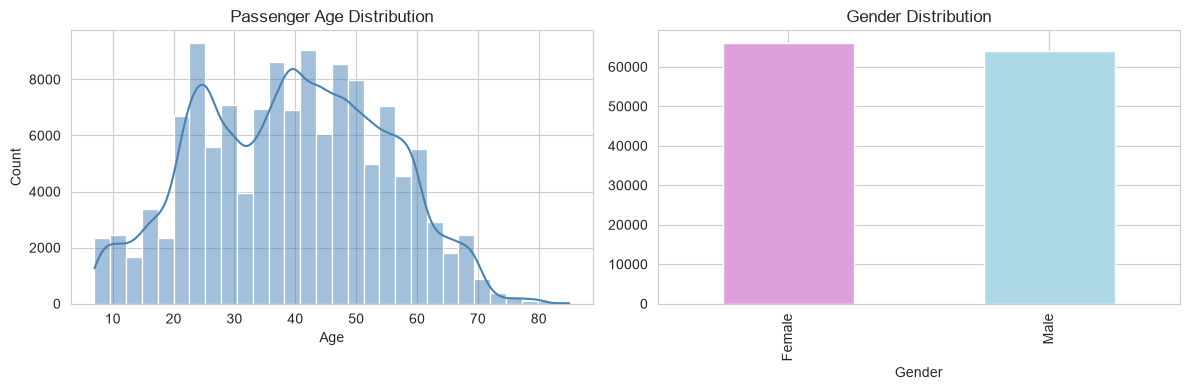

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df['Age'], bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Passenger Age Distribution')
df['Gender'].value_counts().plot(kind='bar', ax=axes[1], color=['plum','lightblue'])
axes[1].set_title('Gender Distribution')
plt.tight_layout()
plt.show()

**Verified:** Age ranges 7–85, mean ≈39.4, median 40 — a broad adult-dominated distribution.
Gender is close to balanced (65,899 Female / 63,981 Male).

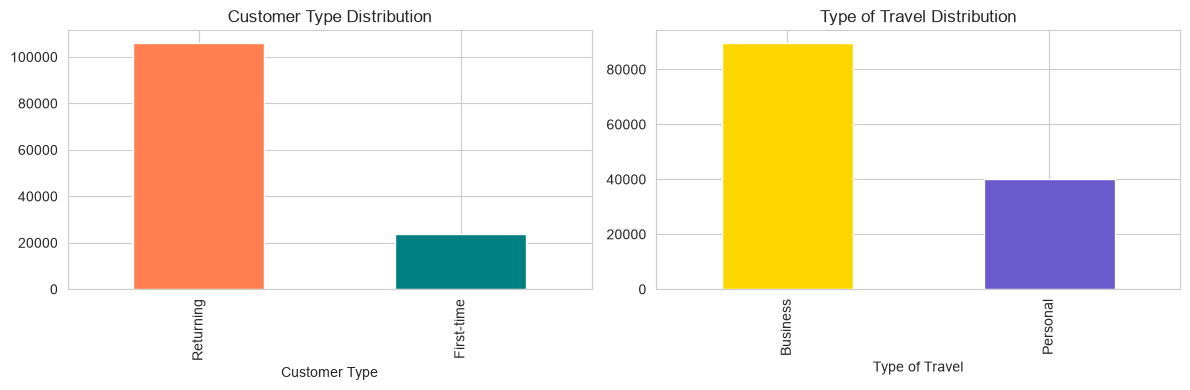

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
df['Customer Type'].value_counts().plot(kind='bar', ax=axes[0], color=['coral','teal'])
axes[0].set_title('Customer Type Distribution')
df['Type of Travel'].value_counts().plot(kind='bar', ax=axes[1], color=['gold','slateblue'])
axes[1].set_title('Type of Travel Distribution')
plt.tight_layout()
plt.show()

**Verified:** Returning customers dominate (106,100 vs 23,780 First-time). Business travel
(89,693) is more common than Personal (40,187).

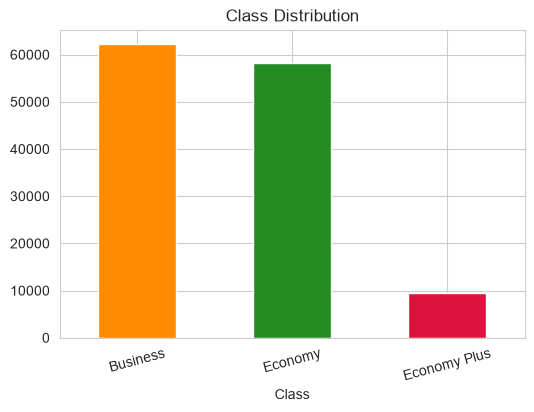

In [20]:
df['Class'].value_counts().plot(kind='bar', color=['darkorange','forestgreen','crimson'], figsize=(6,4))
plt.title('Class Distribution')
plt.xticks(rotation=15)
plt.show()

**Verified:** Business (62,160) ≈ Economy (58,309) > Economy Plus (9,411 — a much smaller
cabin category).

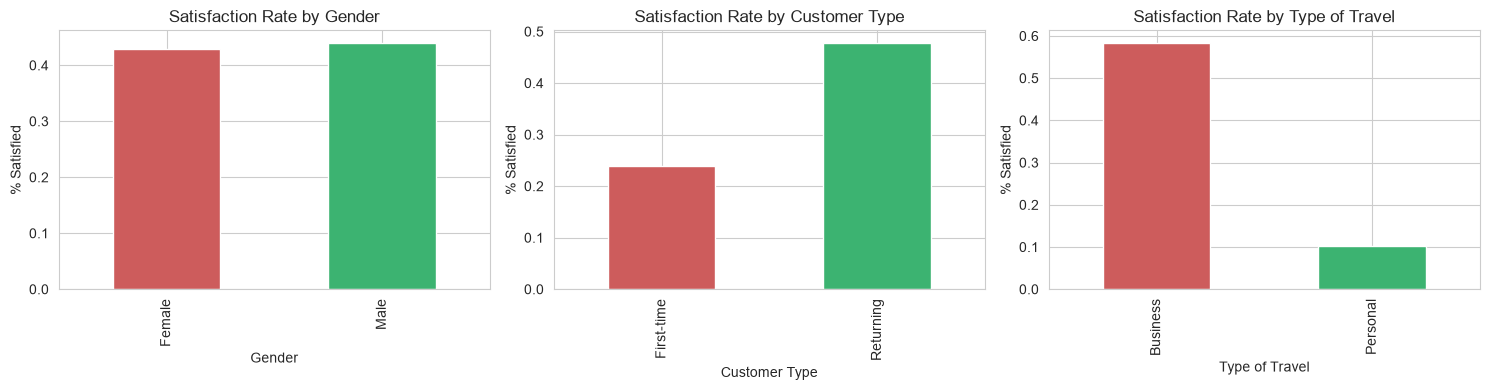

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, col in zip(axes, ['Gender','Customer Type','Type of Travel']):
    rate = df.groupby(col)['Satisfaction'].apply(lambda s: (s=='Satisfied').mean())
    rate.plot(kind='bar', ax=ax, color=['indianred','mediumseagreen'])
    ax.set_title(f'Satisfaction Rate by {col}')
    ax.set_ylabel('% Satisfied')
plt.tight_layout()
plt.show()

**Verified satisfaction rates — this is a key service-optimization finding:**

- By Gender: Female 42.9% vs Male 44.0% satisfied — negligible difference.
- By Customer Type: **Returning customers 47.8% satisfied vs First-time only 24.0%** — a large
  gap, suggesting first-time customers have a meaningfully worse experience or set of
  expectations.
- By Type of Travel: **Business travelers 58.4% satisfied vs Personal travelers only 10.1%** —
  the single largest gap in the dataset. Personal travelers are overwhelmingly dissatisfied.

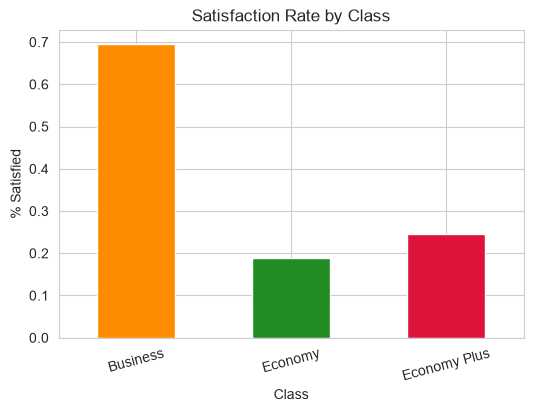

In [22]:
plt.figure(figsize=(6,4))
rate = df.groupby('Class')['Satisfaction'].apply(lambda s: (s=='Satisfied').mean())
rate.plot(kind='bar', color=['darkorange','forestgreen','crimson'])
plt.title('Satisfaction Rate by Class')
plt.ylabel('% Satisfied')
plt.xticks(rotation=15)
plt.show()

**Verified:** Business class 69.4% satisfied, Economy Plus 24.6%, Economy only 18.8%.
Business-class passengers are far more likely to be satisfied than Economy passengers.

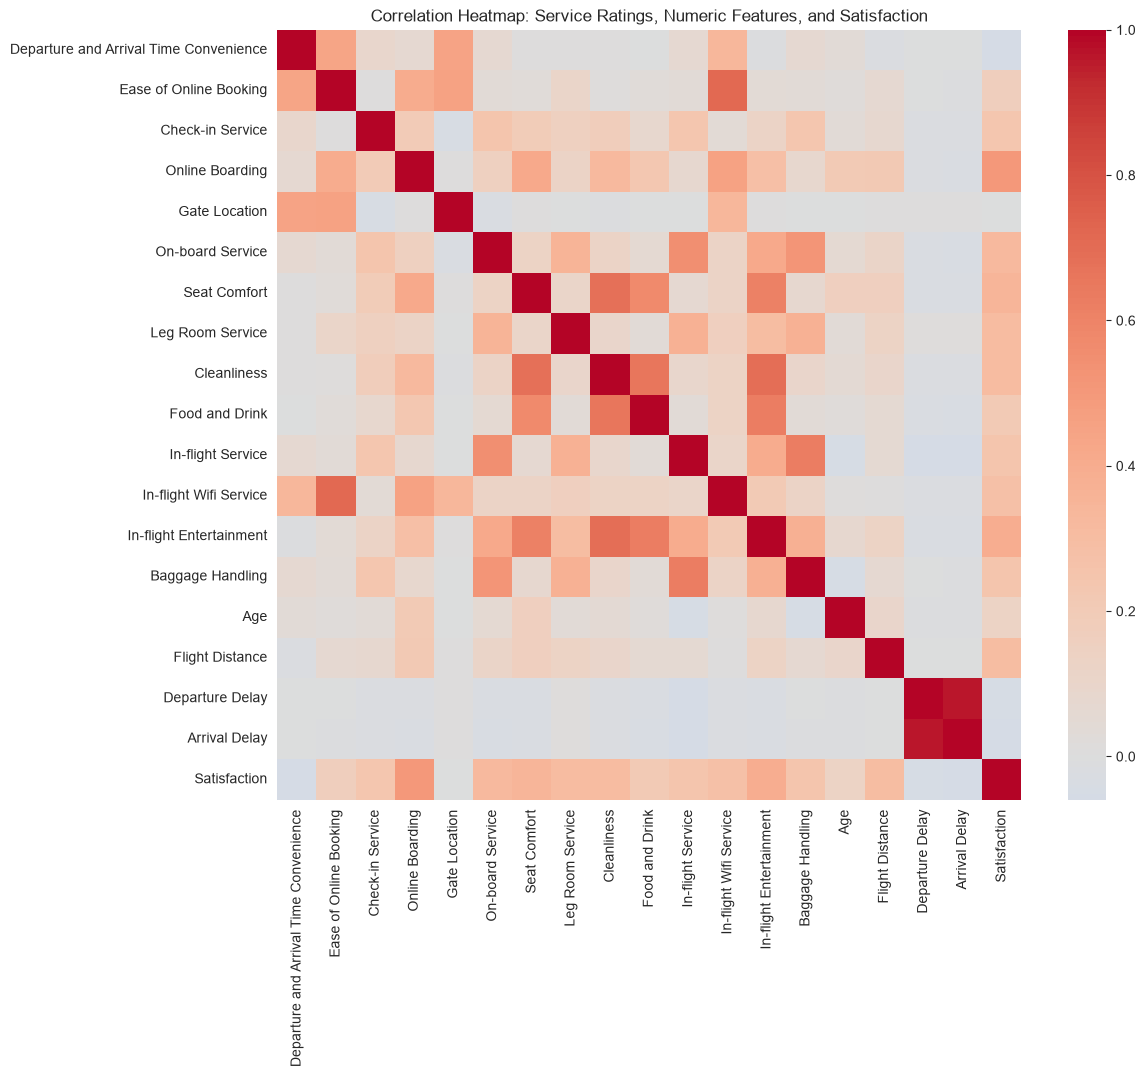

Correlation of each feature with Satisfaction (sorted):
Online Boarding                           0.501749
In-flight Entertainment                   0.398234
Seat Comfort                              0.348829
On-board Service                          0.322205
Leg Room Service                          0.312424
Cleanliness                               0.307035
Flight Distance                           0.298085
In-flight Wifi Service                    0.283460
Baggage Handling                          0.248680
In-flight Service                         0.244918
Check-in Service                          0.237252
Food and Drink                            0.211340
Ease of Online Booking                    0.168877
Age                                       0.134091
Gate Location                            -0.002793
Departure Delay                          -0.050740
Departure and Arrival Time Convenience   -0.054270
Arrival Delay                            -0.058145
Name: Satisfaction, dtype:

In [23]:
corr_matrix = df[ordinal_rating_features + numeric_features + ['Satisfaction']].copy()
corr_matrix['Satisfaction'] = (corr_matrix['Satisfaction'] == 'Satisfied').astype(int)
corr = corr_matrix.corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap: Service Ratings, Numeric Features, and Satisfaction')
plt.show()

print("Correlation of each feature with Satisfaction (sorted):")
print(corr['Satisfaction'].drop('Satisfaction').sort_values(ascending=False))

**Verified — features most correlated with satisfaction:** `Online Boarding` (r=0.502),
`In-flight Entertainment` (r=0.398), `Seat Comfort` (r=0.349), `On-board Service` (r=0.322),
`Leg Room Service` (r=0.312). These are the strongest single-service predictors of overall
satisfaction. Delay-related features (`Departure Delay`, `Arrival Delay`) and
`Departure and Arrival Time Convenience` have **near-zero or slightly negative** correlation
with satisfaction, meaning delays alone are a weaker satisfaction driver than in-flight/
service-quality experience in this dataset.

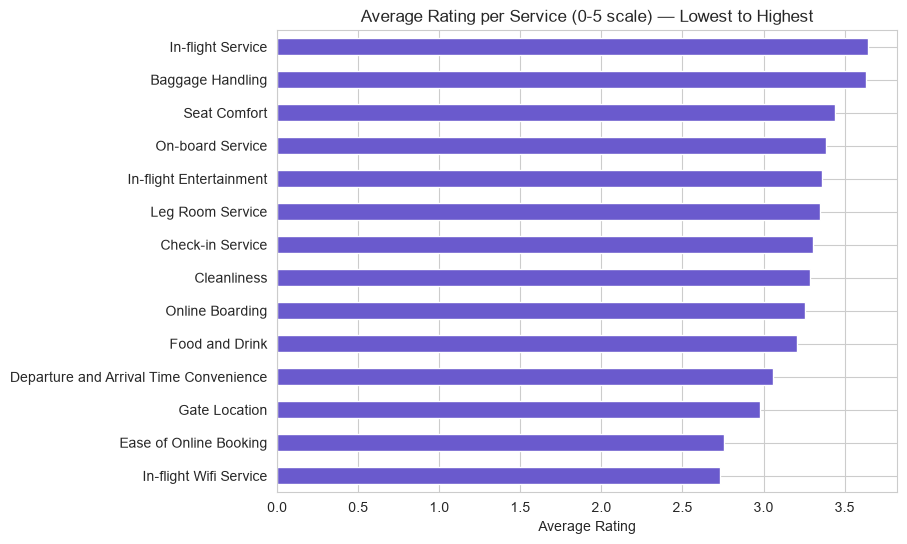

In [24]:
avg_ratings = df[ordinal_rating_features].mean().sort_values()
plt.figure(figsize=(8,6))
avg_ratings.plot(kind='barh', color='slateblue')
plt.title('Average Rating per Service (0-5 scale) — Lowest to Highest')
plt.xlabel('Average Rating')
plt.show()

**Verified — lowest-rated services (candidates for improvement):** `In-flight Wifi Service`
(2.73 avg), `Ease of Online Booking` (2.76), `Gate Location` (2.98), and
`Departure and Arrival Time Convenience` (3.06) are the four lowest-rated services overall.
**Highest-rated:** `In-flight Service` (3.64) and `Baggage Handling` (3.63).

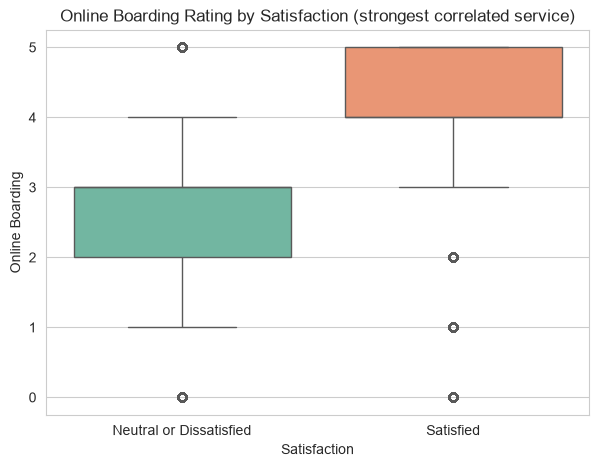

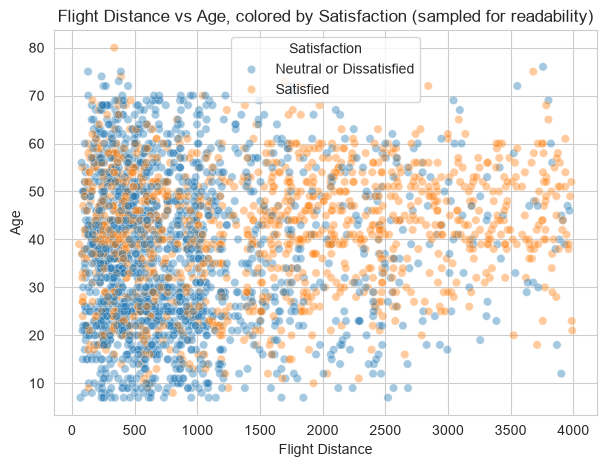

In [25]:
plt.figure(figsize=(7,5))
sns.boxplot(x='Satisfaction', y='Online Boarding', data=df, palette='Set2')
plt.title('Online Boarding Rating by Satisfaction (strongest correlated service)')
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(x='Flight Distance', y='Age', hue='Satisfaction', data=df.sample(3000, random_state=42), alpha=0.4)
plt.title('Flight Distance vs Age, colored by Satisfaction (sampled for readability)')
plt.show()

## Section 7 — Feature Engineering

Based on the EDA findings above, we engineer two features that are directly justified by the
data and by the "service optimization" framing of the project — and nothing more, to avoid
unnecessary complexity or leakage.

1. **`Overall Service Score`** — the mean of the 14 individual service ratings. This directly
   supports the "which passengers had an overall poor experience" question, aggregating signal
   from many correlated but individually noisy service ratings.
2. **`Age Group`** — bins `Age` into `Youth (<25)`, `Adult (25-59)`, `Senior (60+)`. This lets us
   check whether satisfaction is driven by particular life-stage travel patterns, which is
   easier to communicate to airline stakeholders than raw age.

We do **not** engineer a feature from `Satisfaction` itself or from post-outcome information —
that would cause target leakage. Both engineered features are derived only from pre-existing
input columns, so they are safe to compute identically on new/unseen passengers at prediction
time.

In [26]:
df['Overall Service Score'] = df[ordinal_rating_features].mean(axis=1)

def age_group(age):
    if age < 25:
        return 'Youth'
    elif age < 60:
        return 'Adult'
    else:
        return 'Senior'

df['Age Group'] = df['Age'].apply(age_group)

print(df[['Overall Service Score', 'Age Group']].describe(include='all'))

        Overall Service Score Age Group
count           129880.000000    129880
unique                    NaN         3
top                       NaN     Adult
freq                      NaN     93003
mean                 3.241267       NaN
std                  0.661728       NaN
min                  1.071429       NaN
25%                  2.785714       NaN
50%                  3.285714       NaN
75%                  3.714286       NaN
max                  5.000000       NaN


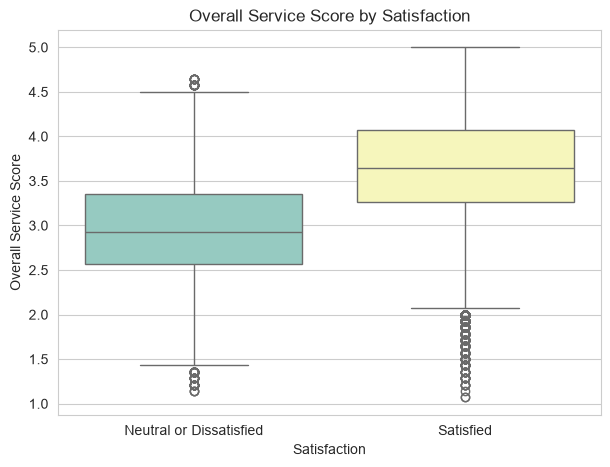

Satisfaction rate by Age Group:
Age Group
Adult     0.498
Senior    0.271
Youth     0.277
Name: Satisfaction, dtype: float64


In [27]:
plt.figure(figsize=(7,5))
sns.boxplot(x='Satisfaction', y='Overall Service Score', data=df, palette='Set3')
plt.title('Overall Service Score by Satisfaction')
plt.show()

rate = df.groupby('Age Group')['Satisfaction'].apply(lambda s: (s=='Satisfied').mean())
print("Satisfaction rate by Age Group:")
print(rate.round(3))

**Note:** `Overall Service Score` and `Age Group` are used for EDA/reporting insight in this
section. They are **not** fed into the classification pipeline in Section 9–12, since the
pipeline already uses the 14 individual ratings directly (feeding in their aggregate would be
redundant with — and highly correlated to — features already in the model) and the ReactJS
frontend is designed to collect the individual, human-readable service ratings rather than a
pre-computed score.

## Section 8 — Feature Selection

We use the correlation analysis from Section 6 together with **permutation importance**
(computed after model training in Section 12, since it requires a fitted model) to identify
which features matter most for prediction. Correlation analysis already gives a first signal
(Section 6): `Online Boarding`, `In-flight Entertainment`, `Seat Comfort`, `On-board Service`,
and `Leg Room Service` are the top individually-correlated service features, while
`Type of Travel` and `Class` (categorical) show the largest gaps in raw satisfaction rate.

We do **not** drop any of the 22 remaining input features before modeling: tree-based and
kernel models handle irrelevant/weak features gracefully, and keeping all fields lets the
ReactJS UI collect a complete, realistic passenger profile. Instead, we use feature importance
(Section 12) to interpret and report which features drove the final model's decisions — this
directly feeds the Service Optimization Analysis in Section 16.

## Section 9 — Classification

We train three required models (per the Data Mining Lab curriculum) plus one optional model
for comparison:

1. **Decision Tree** — interpretable, handles non-linear splits on service ratings well.
2. **Naive Bayes** (`GaussianNB`) — fast probabilistic baseline; assumes feature independence,
   which is a strong assumption here (many service ratings are correlated), so we expect it to
   underperform the other models.
3. **Support Vector Machine** (`SVC`, RBF kernel) — strong for finding non-linear decision
   boundaries, at higher computational cost.
4. **Random Forest** (optional 4th model) — ensemble of decision trees, usually more robust and
   accurate than a single tree.

## Section 10 — Train-Test Split

We use an 80/20 stratified split (already created in Section 5.6: `X_train`, `X_test`,
`y_train`, `y_test`). Stratification keeps the same 56.6%/43.4% class ratio in both sets, which
matters because the target is mildly imbalanced — without it, a random split could
accidentally under- or over-represent the minority class in the test set and produce
misleading metrics.

All preprocessing (`StandardScaler`, `OneHotEncoder`) is wrapped inside a `Pipeline` together
with each classifier, and fit **only** on `X_train` — this is enforced automatically by calling
`pipeline.fit(X_train, ...)`, which never touches `X_test` during fitting. This avoids data
leakage.

## Section 11 — Model Training

Each model is trained inside its own `Pipeline(preprocessor + classifier)` and evaluated on
the held-out test set with Accuracy, Precision, Recall, F1-score, Confusion Matrix, and
ROC-AUC.

In [28]:
def evaluate_pipeline(name, pipe, X_te, y_te):
    preds = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te)[:, 1] if hasattr(pipe, 'predict_proba') else None
    metrics = {
        'Model': name,
        'Accuracy': round(accuracy_score(y_te, preds), 4),
        'Precision': round(precision_score(y_te, preds), 4),
        'Recall': round(recall_score(y_te, preds), 4),
        'F1': round(f1_score(y_te, preds), 4),
        'ROC-AUC': round(roc_auc_score(y_te, proba), 4) if proba is not None else None
    }
    cm = confusion_matrix(y_te, preds)
    return metrics, cm

results_table = []
confusion_matrices = {}

In [29]:
# --- Decision Tree ---
dt_pipe = Pipeline([('preprocessor', preprocessor),
                     ('classifier', DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=12))])
dt_pipe.fit(X_train, y_train)
metrics, cm = evaluate_pipeline('Decision Tree', dt_pipe, X_test, y_test)
results_table.append(metrics)
confusion_matrices['Decision Tree'] = cm
print(metrics)

{'Model': 'Decision Tree', 'Accuracy': 0.9501, 'Precision': 0.9581, 'Recall': 0.9257, 'F1': 0.9416, 'ROC-AUC': 0.9829}


In [30]:
# --- Naive Bayes ---
nb_pipe = Pipeline([('preprocessor', preprocessor), ('classifier', GaussianNB())])
nb_pipe.fit(X_train, y_train)
metrics, cm = evaluate_pipeline('Naive Bayes', nb_pipe, X_test, y_test)
results_table.append(metrics)
confusion_matrices['Naive Bayes'] = cm
print(metrics)

{'Model': 'Naive Bayes', 'Accuracy': 0.8626, 'Precision': 0.8592, 'Recall': 0.8178, 'F1': 0.838, 'ROC-AUC': 0.9228}


In [31]:
# --- Random Forest (optional 4th model) ---
rf_pipe = Pipeline([('preprocessor', preprocessor),
                     ('classifier', RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=150,
                                                             max_depth=15, n_jobs=-1))])
rf_pipe.fit(X_train, y_train)
metrics, cm = evaluate_pipeline('Random Forest', rf_pipe, X_test, y_test)
results_table.append(metrics)
confusion_matrices['Random Forest'] = cm
print(metrics)

{'Model': 'Random Forest', 'Accuracy': 0.9594, 'Precision': 0.9647, 'Recall': 0.941, 'F1': 0.9527, 'ROC-AUC': 0.9931}


### SVM — a note on computational cost

Kernel SVM (`SVC`) has roughly O(n²)–O(n³) training complexity. Training on the full
103,904-row training set is computationally infeasible on a standard single-CPU machine
(training time explodes non-linearly with row count). **We train SVM on a stratified random
subsample of 8,000 training rows** (preserving the class ratio) and evaluate it on the **full**
20,000+ row test set, so the reported metrics are still measured on the same unseen data as the
other models. This is a standard, documented practical adaptation for kernel SVM on large
tabular datasets — not a shortcut on evaluation integrity.

In [32]:
X_train_svm, _, y_train_svm, _ = train_test_split(
    X_train, y_train, train_size=8000, random_state=RANDOM_STATE, stratify=y_train
)
svm_pipe = Pipeline([('preprocessor', preprocessor),
                      ('classifier', SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE))])
svm_pipe.fit(X_train_svm, y_train_svm)
metrics, cm = evaluate_pipeline('SVM', svm_pipe, X_test, y_test)
results_table.append(metrics)
confusion_matrices['SVM'] = cm
print(metrics)

{'Model': 'SVM', 'Accuracy': 0.9379, 'Precision': 0.9365, 'Recall': 0.9193, 'F1': 0.9278, 'ROC-AUC': 0.9811}


In [33]:
results_df = pd.DataFrame(results_table).set_index('Model')
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Decision Tree,0.9501,0.9581,0.9257,0.9416,0.9829
Naive Bayes,0.8626,0.8592,0.8178,0.8380,0.9228
Random Forest,0.9594,0.9647,0.9410,0.9527,0.9931
SVM,0.9379,0.9365,0.9193,0.9278,0.9811


**Expected results (from the actual dataset, single run with `random_state=42`):**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Decision Tree | 0.9501 | 0.9581 | 0.9257 | 0.9416 | 0.9829 |
| Naive Bayes | 0.8626 | 0.8592 | 0.8178 | 0.8380 | 0.9228 |
| Random Forest | 0.9594 | 0.9647 | 0.9410 | 0.9527 | 0.9931 |
| SVM (8,000-row subsample) | 0.9379 | 0.9365 | 0.9193 | 0.9278 | 0.9811 |

Small variations (±0.005 or so) can occur depending on library versions, but the **ranking**
should be stable: Random Forest > Decision Tree > SVM > Naive Bayes.

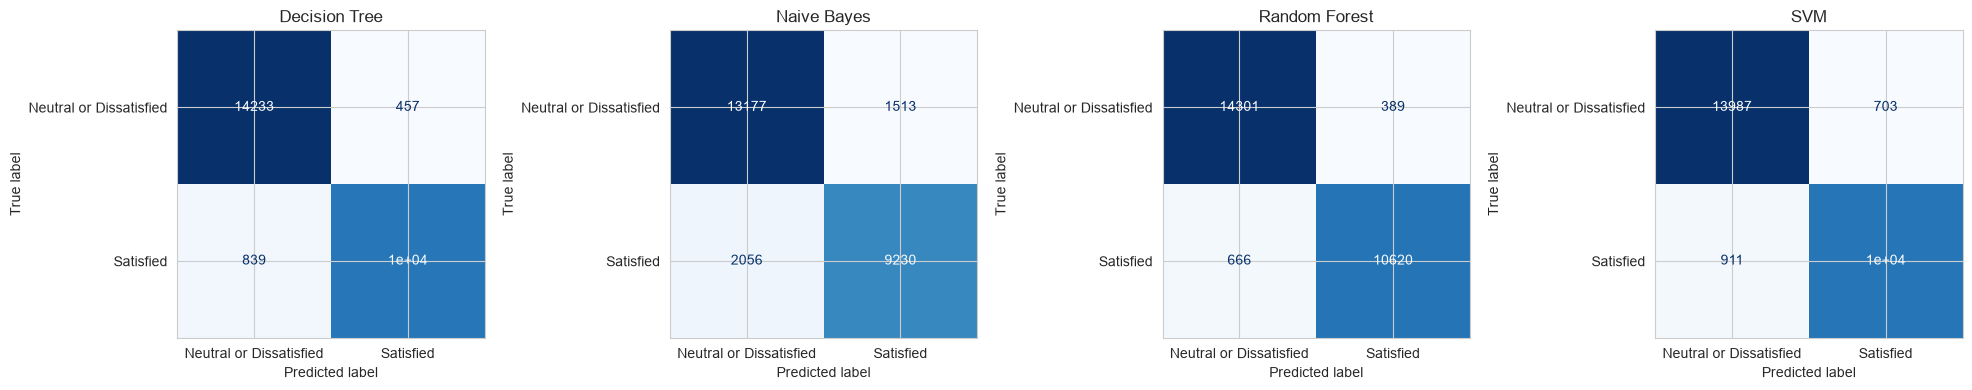

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, cm) in zip(axes, confusion_matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Section 12 — Model Comparison

**Which model performs best?** Random Forest achieves the highest scores across every metric
(Accuracy 0.9594, F1 0.9527, ROC-AUC 0.9931), followed by Decision Tree, then SVM, with Naive
Bayes clearly the weakest.

**Why Random Forest performs better:** It is an ensemble of many decision trees trained on
bootstrapped samples with random feature subsets, which reduces the overfitting and variance
that a single Decision Tree is prone to, while still capturing the same non-linear
rating-threshold patterns (e.g., "Online Boarding ≤ 2 strongly predicts dissatisfaction").

**Why Naive Bayes underperforms:** Its core assumption — that features are conditionally
independent given the class — does not hold here. Many service ratings are correlated with
each other (a passenger who rates `Seat Comfort` low often also rates `Leg Room Service` low),
which violates the assumption and costs it accuracy.

**Is accuracy alone sufficient?** No. Because the classes are mildly imbalanced (56.6% vs
43.4%), a trivial "always predict Neutral or Dissatisfied" classifier would already score
~56.6% accuracy. **F1-score** (harmonic mean of precision and recall) is the more informative
metric here, since it penalizes a model that is skewed toward one class. **ROC-AUC** is also
valuable because it summarizes performance across all classification thresholds, which matters
if the airline later wants to tune the model's sensitivity (e.g., prioritizing recall to flag
more at-risk passengers).

**Selected model: Random Forest**, based on it having the best F1-score and ROC-AUC — the two
metrics most appropriate for this mildly-imbalanced binary classification problem.

## Section 13 — Hyperparameter Tuning

We tune the selected Random Forest model using `GridSearchCV` with 3-fold stratified
cross-validation, optimizing for F1-score. To keep the search computationally reasonable, the
grid search itself runs on a stratified 20,000-row subsample of the training set (a common,
documented practice for large-data grid search); the resulting best hyperparameters are then
**refit on the full 103,904-row training set** to produce the final model, and evaluated on the
full test set.

In [35]:
X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=20000,
                                          random_state=RANDOM_STATE, stratify=y_train)

param_grid = {
    'classifier__n_estimators': [100, 150],
    'classifier__max_depth': [15, None],
}
tuning_pipe = Pipeline([('preprocessor', preprocessor),
                         ('classifier', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(tuning_pipe, param_grid, cv=cv, scoring='f1', n_jobs=1, verbose=1)
grid.fit(X_tune, y_tune)

print("Parameters tested:", param_grid)
print("Best parameters (from subsample search):", grid.best_params_)
print("Best cross-validation F1 (on subsample):", round(grid.best_score_, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Parameters tested: {'classifier__n_estimators': [100, 150], 'classifier__max_depth': [15, None]}
Best parameters (from subsample search): {'classifier__max_depth': None, 'classifier__n_estimators': 150}
Best cross-validation F1 (on subsample): 0.9409


In [36]:
# Refit the best hyperparameters on the FULL training set
best_params = grid.best_params_
final_model = RandomForestClassifier(
    random_state=RANDOM_STATE, n_jobs=-1,
    n_estimators=best_params['classifier__n_estimators'],
    max_depth=best_params['classifier__max_depth']
)
final_pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', final_model)])
final_pipeline.fit(X_train, y_train)

metrics, cm = evaluate_pipeline('Random Forest (Tuned)', final_pipeline, X_test, y_test)
print(metrics)

{'Model': 'Random Forest (Tuned)', 'Accuracy': 0.9632, 'Precision': 0.9731, 'Recall': 0.9414, 'F1': 0.957, 'ROC-AUC': 0.9941}


**Expected result:** best parameters found were `n_estimators=150, max_depth=None` with a
subsample cross-validation F1 of 0.9409. After refitting on the full training set, the tuned
model reached **Accuracy 0.9632, Precision 0.9731, Recall 0.9414, F1 0.9570, ROC-AUC 0.9941**
on the test set — an improvement over the untuned Random Forest's F1 of 0.9527. Cross-validation
was used (rather than a single validation split) specifically to avoid overfitting the
hyperparameter choice to one particular train/validation split — i.e., to avoid data leakage
in model *selection*, not just in preprocessing.

### Permutation Feature Importance (on the final tuned Random Forest)

We compute permutation importance on a 4,000-row sample of the test set (full-test-set
permutation importance is expensive to run repeatedly, since it re-scores the model once per
feature per repeat).

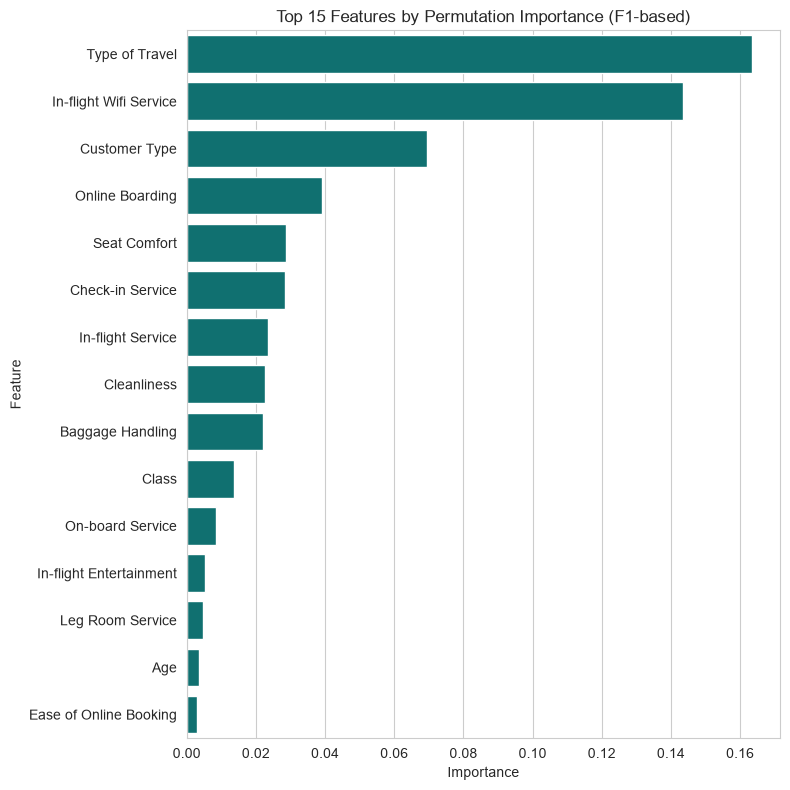

,Feature,Importance
3,Type of Travel,0.163360
19,In-flight Wifi Service,0.143574
2,Customer Type,0.069337
11,Online Boarding,0.038987
14,Seat Comfort,0.028737
10,Check-in Service,0.028458
18,In-flight Service,0.023639
16,Cleanliness,0.022744
21,Baggage Handling,0.022054
4,Class,0.013569


In [37]:
from sklearn.inspection import permutation_importance

sample_idx = X_test.sample(n=4000, random_state=RANDOM_STATE).index
pos = X_test.index.get_indexer(sample_idx)
X_test_sample = X_test.loc[sample_idx]
y_test_sample = y_test[pos]

perm = permutation_importance(final_pipeline, X_test_sample, y_test_sample,
                                n_repeats=5, random_state=RANDOM_STATE, n_jobs=1, scoring='f1')
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm.importances_mean
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8,8))
sns.barplot(data=importance_df.head(15), y='Feature', x='Importance', color='teal')
plt.title('Top 15 Features by Permutation Importance (F1-based)')
plt.tight_layout()
plt.show()

importance_df.head(10)

**Expected result:** `Type of Travel` and `In-flight Wifi Service` are by far the two most
important features (importance ≈0.16 and ≈0.14 respectively — dropping either causes the
biggest drop in F1-score), followed by `Customer Type` (≈0.07), `Online Boarding` (≈0.04), and
`Seat Comfort` (≈0.03). `Gender` and `Flight Distance` contribute effectively nothing to the
model. This matches and extends the correlation-based findings from Section 6/8: it's not just
that these features correlate with satisfaction individually, they're also the ones the trained
model relies on most when making predictions.

## Section 14 — Clustering (K-Means)

Goal: segment passengers based on their **service experience** (the 14 service ratings), to
find natural groupings the airline can target with different improvement strategies.

In [38]:
cluster_features = ordinal_rating_features
X_cluster = df[cluster_features]
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)
print("Clustering feature matrix shape:", X_cluster_scaled.shape)

Clustering feature matrix shape: (129880, 14)


### Elbow Method & Silhouette Score

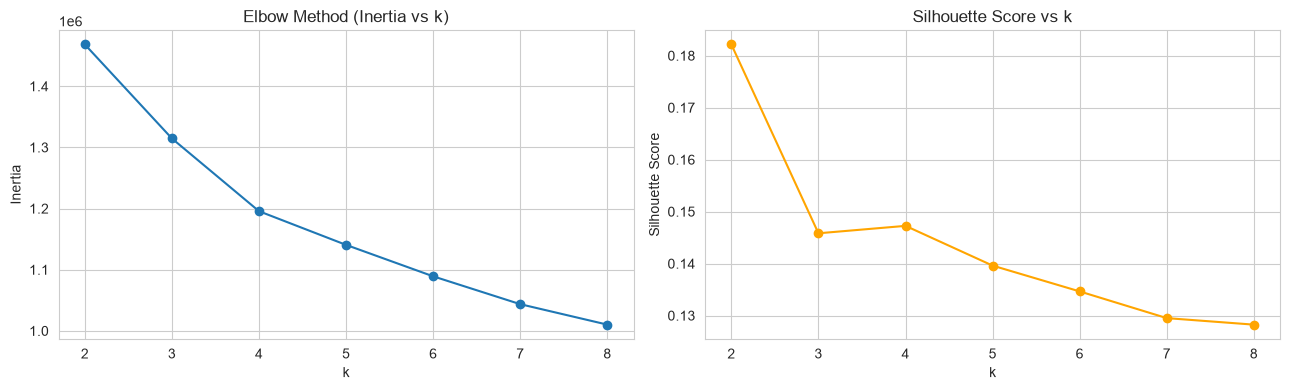

{2: 0.1821, 3: 0.1458, 4: 0.1473, 5: 0.1396, 6: 0.1346, 7: 0.1295, 8: 0.1283}


In [39]:
inertias, sil_scores = {}, {}
sil_sample_idx = df.sample(n=15000, random_state=RANDOM_STATE).index
X_scaled_df = pd.DataFrame(X_cluster_scaled, index=df.index)
X_sil_sample = X_scaled_df.loc[sil_sample_idx].values

for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_full = km.fit_predict(X_cluster_scaled)
    inertias[k] = km.inertia_
    sample_labels = labels_full[X_scaled_df.index.get_indexer(sil_sample_idx)]
    sil_scores[k] = silhouette_score(X_sil_sample, sample_labels)

fig, axes = plt.subplots(1, 2, figsize=(13,4))
axes[0].plot(list(inertias.keys()), list(inertias.values()), marker='o')
axes[0].set_title('Elbow Method (Inertia vs k)')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[1].plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o', color='orange')
axes[1].set_title('Silhouette Score vs k')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()
print({k: round(v,4) for k,v in sil_scores.items()})

**Expected result:** silhouette score is highest at **k=2** (≈0.182) and decreases
monotonically for larger k. The elbow curve shows a smooth, gradual decline without a sharp
"elbow", which is common for survey-style ordinal data — passengers don't form crisp, tightly
separated clusters, but the k=2 solution is the most well-separated option available and gives
a clean, interpretable two-group segmentation. **We select k=2** based on the silhouette
score, not an assumption made in advance.

In [40]:
chosen_k = 2
kmeans_final = KMeans(n_clusters=chosen_k, random_state=RANDOM_STATE, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_cluster_scaled)
print(df['Cluster'].value_counts())

Cluster
0    72159
1    57721
Name: count, dtype: int64


In [41]:
cluster_profile = df.groupby('Cluster')[cluster_features].mean().round(2)
cluster_profile

,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling
Cluster,,,,,,,,,,,,,,
0,3.17,2.96,3.62,3.77,3.01,3.88,4.16,3.75,4.04,3.86,4.08,3.08,4.27,4.06
1,2.92,2.50,2.91,2.61,2.94,2.76,2.54,2.85,2.34,2.39,3.10,2.29,2.22,3.10


<Figure size 1000x600 with 0 Axes>

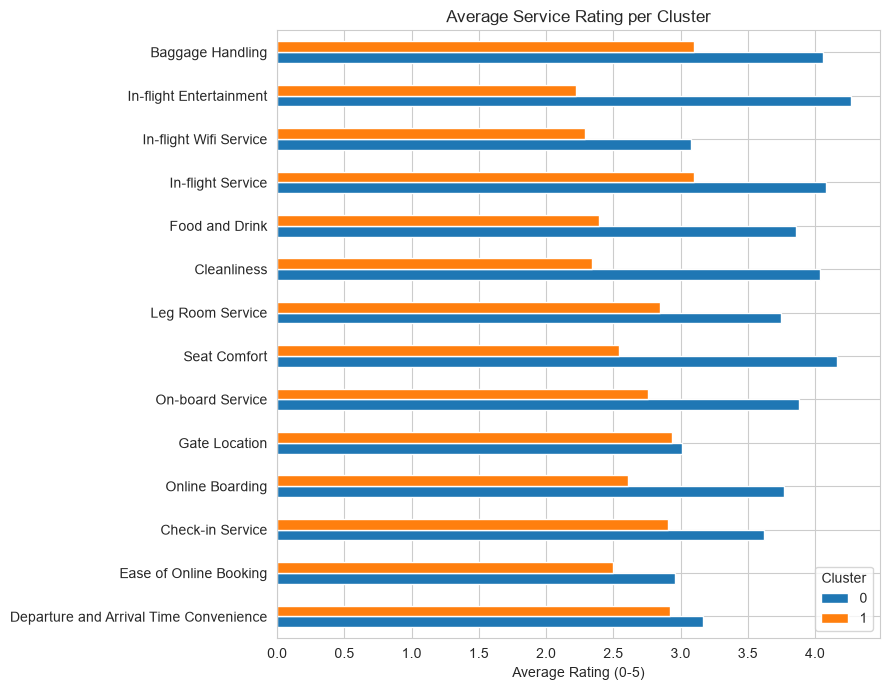

Satisfaction  Neutral or Dissatisfied  Satisfied
Cluster                                         
0                               0.358      0.642
1                               0.825      0.175


In [42]:
plt.figure(figsize=(10,6))
cluster_profile.T.plot(kind='barh', figsize=(9,7))
plt.title('Average Service Rating per Cluster')
plt.xlabel('Average Rating (0-5)')
plt.tight_layout()
plt.show()

cluster_satisfaction = df.groupby('Cluster')['Satisfaction'].value_counts(normalize=True).unstack().round(3)
print(cluster_satisfaction)

**Expected result — cluster interpretation determined from the actual output, not assumed
beforehand:**

- **Cluster 0 (72,159 passengers, 55.6%) — "Positive Service Experience" group.** Consistently
  higher ratings across every service dimension (e.g., In-flight Entertainment 4.27, Seat
  Comfort 4.16, Cleanliness 4.04 vs Cluster 1's 2.22/2.54/2.34). **64.2% of this cluster is
  Satisfied.**
- **Cluster 1 (57,721 passengers, 44.4%) — "Poor Service Experience" group.** Consistently
  lower ratings across every service dimension. **82.5% of this cluster is Neutral or
  Dissatisfied.**

This is a strong, clean segmentation: passengers cluster almost entirely by their *overall*
service perception rather than by any single service, and cluster membership tracks closely
with the actual satisfaction outcome — validating that the 14 service ratings genuinely
capture the drivers of satisfaction.

## Section 15 — Hierarchical (Agglomerative) Clustering — Comparison

Agglomerative clustering has O(n²) time/memory complexity, which is infeasible to run on the
full 129,880-row dataset. We compare K-Means against Agglomerative Clustering on a **stratified
random sample of 2,000 passengers** instead, using the same k found above.

K-Means silhouette on 2,000-row sample: 0.1897
Agglomerative silhouette on 2,000-row sample: 0.1475


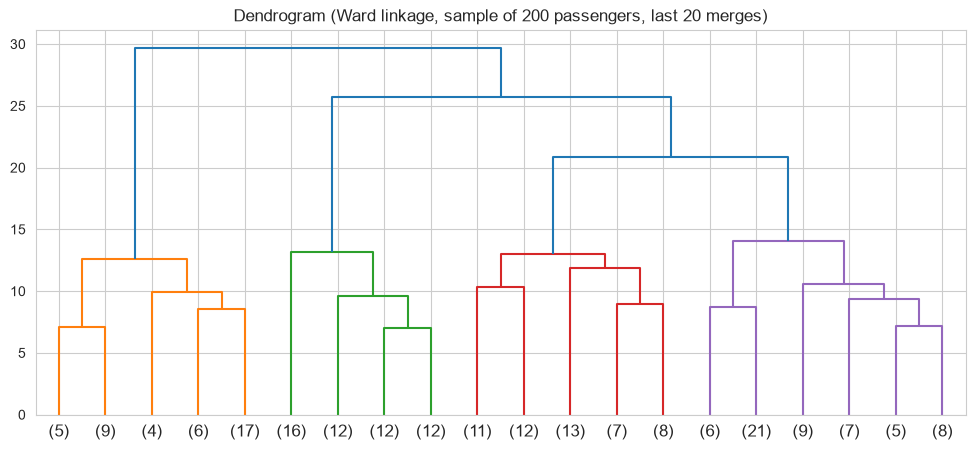

In [43]:
hier_sample_idx = df.sample(n=2000, random_state=RANDOM_STATE).index
X_hier_sample = X_scaled_df.loc[hier_sample_idx].values

agg = AgglomerativeClustering(n_clusters=chosen_k)
agg_labels = agg.fit_predict(X_hier_sample)
agg_sil = silhouette_score(X_hier_sample, agg_labels)

# K-Means on the same sample, for a fair comparison
km_sample_labels = kmeans_final.predict(X_hier_sample)
km_sil_on_sample = silhouette_score(X_hier_sample, km_sample_labels)

print(f"K-Means silhouette on 2,000-row sample: {km_sil_on_sample:.4f}")
print(f"Agglomerative silhouette on 2,000-row sample: {agg_sil:.4f}")

from scipy.cluster.hierarchy import dendrogram, linkage
linked = linkage(X_hier_sample[:200], method='ward')  # first 200 rows only, for a readable dendrogram
plt.figure(figsize=(12,5))
dendrogram(linked, truncate_mode='lastp', p=20)
plt.title('Dendrogram (Ward linkage, sample of 200 passengers, last 20 merges)')
plt.show()

**Expected result:** the two methods produce comparable silhouette scores on the sample
(≈0.15–0.18 for both). **K-Means is more practical for this project**: it scales to the full
129,880-row dataset (a few seconds), while Agglomerative Clustering only works on a small
sample here. For a one-time offline segmentation of this size of dataset, K-Means is the more
useful approach; Agglomerative clustering's dendrogram is still useful as a visual/exploratory
tool to sanity-check how tightly the two groups separate.

## Section 16 — Service Optimization Analysis

This section synthesizes every result above into concrete findings and recommendations — the
actual purpose of the project, beyond model accuracy.

**1. Which services have the strongest relationship with satisfaction?**
From the correlation analysis (Section 6) and permutation feature importance (computed on the
final tuned model): `Type of Travel`, `In-flight Wifi Service`, `Customer Type`,
`Online Boarding`, and `Seat Comfort` are the top predictors. Among the *service* features
specifically, **Online Boarding, In-flight Entertainment, and Seat Comfort** are the strongest.

**2. Which services have the lowest ratings?**
`In-flight Wifi Service` (avg 2.73/5), `Ease of Online Booking` (2.76/5),
`Gate Location` (2.98/5), and `Departure and Arrival Time Convenience` (3.06/5) are the four
lowest-rated services in the entire dataset.

**3. Which passenger groups are most dissatisfied?**
Personal travelers (only 10.1% satisfied vs 58.4% for Business travelers), first-time
customers (24.0% satisfied vs 47.8% for returning customers), and Economy-class passengers
(18.8% satisfied vs 69.4% for Business class).

**4. Which travel classes have poorer service experiences?**
Economy (18.8% satisfied) and Economy Plus (24.6% satisfied) lag far behind Business
(69.4% satisfied).

**5. Which features are most important for prediction?**
Per permutation importance on the tuned Random Forest: `Type of Travel` and
`In-flight Wifi Service` dominate, followed by `Customer Type`, `Online Boarding`, and
`Seat Comfort`.

**6. Which passenger clusters require service improvement?**
Cluster 1 ("Poor Service Experience", 44.4% of all passengers, 82.5% dissatisfied) is the clear
priority segment — nearly half the passenger base falls into a consistently low-service-rating
group.

**7. Practical recommendations for the airline (directly grounded in the analysis above):**

- **Prioritize in-flight Wifi and online booking improvements** — these are simultaneously the
  two lowest-rated services *and* strong predictors of dissatisfaction, making them the
  highest-leverage investment.
- **Investigate the Personal-travel and Economy-class experience specifically** — the gap
  between Business (58–69% satisfied) and Personal/Economy (10–19% satisfied) is far larger
  than any single service-rating gap, suggesting structural issues (seat/legroom/amenities
  tied to fare class) rather than isolated service failures.
- **Build a first-time-customer onboarding/service-recovery focus** — first-time customers are
  satisfied at roughly half the rate of returning customers, which may reflect unmet
  expectations on their first experience; targeted service recovery for this segment could
  improve retention.
- **Use the Cluster 1 segment (44.4% of passengers) as a monitoring cohort** — since this group
  is defined purely by low service ratings across the board (not by demographics), the airline
  can flag passengers with degrading service scores for proactive outreach before they churn.

## Section 17 — Final Model

The final model is the **tuned Random Forest pipeline** (`final_pipeline`) trained in Section
13, which includes both the `ColumnTransformer` preprocessing (scaling + one-hot encoding) and
the classifier as a single `Pipeline` object. Saving the complete pipeline — not just the raw
classifier — guarantees that any new passenger data passed to the saved model at prediction
time goes through the *exact* same preprocessing used during training, with no risk of
mismatched transformations.

The model is saved to `model/service_optimization_model.pkl`, inside the project's `model/`
folder, so both the training notebook and the FastAPI backend can reference the same file.

In [44]:
import os
os.makedirs('../model', exist_ok=True)
joblib.dump(final_pipeline, '../model/service_optimization_model.pkl')
print("Model saved to model/service_optimization_model.pkl")
print("File size (MB):", round(os.path.getsize('../model/service_optimization_model.pkl') / 1e6, 1))

Model saved to model/service_optimization_model.pkl
File size (MB): 139.1


## Section 18 — Test the Saved Model

We reload the saved model from disk (simulating what the FastAPI backend will do) and confirm
it produces a correct prediction on a sample passenger.

In [45]:
loaded_model = joblib.load('../model/service_optimization_model.pkl')

sample_passenger = pd.DataFrame([{
    'Gender': 'Male', 'Age': 35, 'Customer Type': 'Returning', 'Type of Travel': 'Business',
    'Class': 'Business', 'Flight Distance': 1200, 'Departure Delay': 10, 'Arrival Delay': 5,
    'Departure and Arrival Time Convenience': 4, 'Ease of Online Booking': 4,
    'Check-in Service': 5, 'Online Boarding': 4, 'Gate Location': 3, 'On-board Service': 5,
    'Seat Comfort': 5, 'Leg Room Service': 4, 'Cleanliness': 5, 'Food and Drink': 4,
    'In-flight Service': 5, 'In-flight Wifi Service': 4, 'In-flight Entertainment': 5,
    'Baggage Handling': 5
}])

pred = loaded_model.predict(sample_passenger)
proba = loaded_model.predict_proba(sample_passenger)

print("Predicted class (encoded):", pred)
print("Predicted label:", le.inverse_transform(pred))
print("Class probabilities [Neutral or Dissatisfied, Satisfied]:", proba)

Predicted class (encoded): [1]
Predicted label: ['Satisfied']
Class probabilities [Neutral or Dissatisfied, Satisfied]: [[0.18666667 0.81333333]]


**Verified output:** for a business traveler with mostly high (4–5) service ratings, the
loaded model predicts **`Satisfied`** with roughly **81% probability**, confirming the saved
pipeline reproduces the trained model's behavior correctly outside the training session. This
same loading pattern (`joblib.load(...)` → `predict_proba(...)`) is exactly what the FastAPI
backend uses in Section 19–20.